# 06 · Experiment D — leakage, and runtime (protocol validity, RQ3)

**Part 1 — leakage.** Can the sanity check catch leakage before any probe reports signal, and what happens when it cannot?

| Case | Construction | Expected |
|---|---|---|
| Identifier column | null synthetic data + a unique integer row ID | flagged (identifier-like) |
| Crude leak | null synthetic data + a copy of Y with 0.5 % of values flipped | flagged (single-feature AUC > 0.99) |
| Subtle leak | null synthetic data + a copy of Y with 10 % of values flipped | **not** flagged by the 0.99 rule; probes will report signal |
| Real post-outcome leak | NSW + `re78` (earnings measured *after* the randomised treatment) | not flagged; can probes detect the leak? |
| Real deterministic leak | Thornton + `tinc` (incentive amount; `tinc > 0` exactly when the target is 1) | flagged (single-feature AUC = 1) |

**Part 2 — runtime (H3).** Wall-clock cost of each probe on subsamples of Adult of increasing size, relative to cross-validating the reference gradient-boosting model on the same rows.

In [1]:
import json
def load_library_source(path="01_probe_library.ipynb"):
    """Concatenate the code cells of the library notebook so they can be executed here."""
    nb = json.load(open(path, encoding="utf-8"))
    return "\n\n".join("".join(c["source"]) for c in nb["cells"] if c["cell_type"] == "code")

_LIBRARY_IMPORT = True
exec(compile(load_library_source(), "probe_library", "exec"))
import matplotlib.pyplot as plt

## Part 1 · Leakage

### 1.1 Sanity check on constructed and real cases

In [2]:
rng = np.random.default_rng(99)
null = make_synthetic("null", 1000, n_noise=20, seed=4242)
null_df = pd.DataFrame(null.X, columns=null.feature_names)
null_df["y"] = null.y

def with_column(df, name, values):
    out = df.drop(columns="y").copy()
    out[name] = values
    out["y"] = df.y.to_numpy()
    return out

def flipped_copy(y, rate, rng):
    y2 = y.copy()
    idx = rng.choice(len(y), int(rate * len(y)), replace=False)
    y2[idx] = 1 - y2[idx]
    return y2

cases = {
    "Null synthetic (control)": null_df,
    "Null + identifier column": with_column(null_df, "row_id", rng.permutation(len(null_df))),
    "Null + crude leak (0.5% flipped copy of y)": with_column(null_df, "leak", flipped_copy(null_df.y.to_numpy(), 0.005, rng)),
    "Null + subtle leak (10% flipped copy of y)": with_column(null_df, "leak", flipped_copy(null_df.y.to_numpy(), 0.10, rng)),
    "NSW pre-treatment only": load_processed("nsw_null"),
    "NSW + re78 (post-treatment)": load_processed("nsw_leak"),
    "Thornton pre-treatment only": load_processed("thornton_null"),
    "Thornton + village": load_processed("thornton_village"),
    "Thornton + tinc (incentive amount)": load_processed("thornton_leak"),
    "Adult": load_processed("adult"),
    "Pima": load_processed("pima"),
    "Banknote": load_processed("banknote"),
    "Breast cancer": load_processed("breast_cancer"),
}
san = pd.DataFrame({k: sanity_check(v) for k, v in cases.items()}).T
san.to_csv(os.path.join(RESULTS_DIR, "expD_sanity.csv"))
san[["verdict", "id_like_columns", "flagged_features", "exact_duplicates", "best_single_feature", "max_single_feature_auc"]]

,verdict,id_like_columns,flagged_features,exact_duplicates,best_single_feature,max_single_feature_auc
Null synthetic (control),clean,[],[],0,x7,0.542775
Null + identifier column,leakage suspected,[row_id],[],0,x7,0.542775
Null + crude leak (0.5% flipped copy of y),leakage suspected,[],[leak],0,leak,0.994992
Null + subtle leak (10% flipped copy of y),clean,[],[],0,leak,0.90009
NSW pre-treatment only,clean,[],[],73,nodegree,0.563254
NSW + re78 (post-treatment),clean,[],[],15,re78,0.569699
Thornton pre-treatment only,clean,[],[],45,age,0.522695
Thornton + village,clean,[],[],45,villnum,0.658749
Thornton + tinc (incentive amount),leakage suspected,[],[tinc],11,tinc,1.0
Adult,clean,[],[],52,relationship,0.777963


### 1.2 What the probes report when leakage is missed

The probes are run with permutation tests on the cases the sanity check passed: the subtle synthetic leak, and NSW with and without `re78`.

In [3]:
def leak_job(name, df, probe, B):
    r = run_probe(probe, from_dataframe(df, name), B=B, seed=7)
    r["case"] = name
    return r

cache = os.path.join(RESULTS_DIR, "expD_probes.csv")
if os.path.exists(cache):
    leak = pd.read_csv(cache)
else:
    sel = ["Null synthetic (control)", "Null + subtle leak (10% flipped copy of y)", "NSW pre-treatment only", "NSW + re78 (post-treatment)"]
    jobs = [(c, cases[c], pr, 100 if pr.name in ("M3_Forest", "M4_HGB") else 500) for c in sel for pr in all_probes()]
    leak = pd.DataFrame(Parallel(n_jobs=2)(delayed(leak_job)(*j) for j in jobs))
    leak.to_csv(cache, index=False)
leak_wide = leak.pivot(index="probe", columns="case", values="p").loc[PROBE_ORDER]
leak_wide.round(4)

case,NSW + re78 (post-treatment),NSW pre-treatment only,Null + subtle leak (10% flipped copy of y),Null synthetic (control)
probe,,,,
S1_MI,0.0180,0.0160,0.0259,0.0499
S2_ANOVA_Chi2,0.0193,0.0172,0.0000,0.3002
S3_dCor,0.0080,0.0120,0.0020,0.5788
S4_HSIC,0.0160,0.0279,0.0020,0.5948
G1_F1,0.0080,0.0080,0.0020,0.2675
G2_N1,0.0180,0.8882,0.0020,0.9082
G3_N3,0.0180,0.5070,0.0020,0.6527
M1_Tree,0.0659,0.0339,0.0020,0.9142
M2_LogReg,0.0040,0.0379,0.0020,0.4331


In [4]:
nsw_leak = from_dataframe(cases["NSW + re78 (post-treatment)"], "nsw_leak")
pv = AnovaChi2Probe().pvalues(nsw_leak, nsw_leak.y)
pd.DataFrame({"feature": nsw_leak.feature_names, "p_value": pv}).sort_values("p_value").round(4)

,feature,p_value
5,nodegree,0.0021
8,re78,0.0048
1,educ,0.0343
3,hisp,0.1089
0,age,0.2648
7,re75,0.3823
4,marr,0.3936
2,black,0.7440
6,re74,0.9823


## Part 2 · Runtime

For each subsample size, every probe's *observed* statistic is timed once (probes respect their row caps), and the reference cost is one 5-fold cross-validation of the gradient-boosting model on all rows of that subsample. A full permutation test costs roughly (B + 1) × the observed-statistic time; for the model-free probes the label-independent preparation is done once, so their full test is much cheaper than that bound.

In [5]:
cache = os.path.join(RESULTS_DIR, "runtime.csv")
if os.path.exists(cache):
    rt = pd.read_csv(cache)
else:
    adult = from_dataframe(load_processed("adult"), "adult")
    rows = []
    for size in [1000, 5000, 10000, 20000, adult.n]:
        d = subsample(adult, size, np.random.default_rng(size))
        t0 = time.perf_counter()
        cv_auc("hgb", d.X, d.y)
        ref = time.perf_counter() - t0
        for name, (val, sec) in observed_statistics(d, seed=1).items():
            rows.append({"n": d.n, "probe": name, "seconds_observed": sec, "reference_hgb_cv_seconds": ref})
        # full permutation test time for the model-free probes (B = 200), which reuse their preparation
        for pr in all_probes()[:7]:
            if getattr(pr, "parametric", False):
                continue
            r = run_probe(pr, d, B=200, seed=1)
            rows.append({"n": d.n, "probe": pr.name + " (full test, B=200)", "seconds_observed": r["seconds_total"],
                         "reference_hgb_cv_seconds": ref})
    rt = pd.DataFrame(rows)
    rt.to_csv(cache, index=False)
rt["relative_to_hgb_cv"] = rt.seconds_observed / rt.reference_hgb_cv_seconds
rt.pivot(index="probe", columns="n", values="relative_to_hgb_cv").round(3)

n,1000,5000,10000,20000,48842
probe,,,,,
G1_F1,0.001,0.004,0.002,0.002,0.000
"G1_F1 (full test, B=200)",0.068,0.223,0.125,0.101,0.047
G2_N1,0.100,1.849,1.305,1.189,0.445
"G2_N1 (full test, B=200)",0.093,1.984,1.342,1.184,0.489
G3_N3,0.010,0.045,0.034,0.027,0.011
"G3_N3 (full test, B=200)",0.007,0.050,0.034,0.032,0.012
M1_Tree,0.010,0.017,0.022,0.018,0.009
M2_LogReg,0.041,0.076,0.087,0.075,0.031
M3_Forest,0.208,0.207,0.317,0.252,0.102


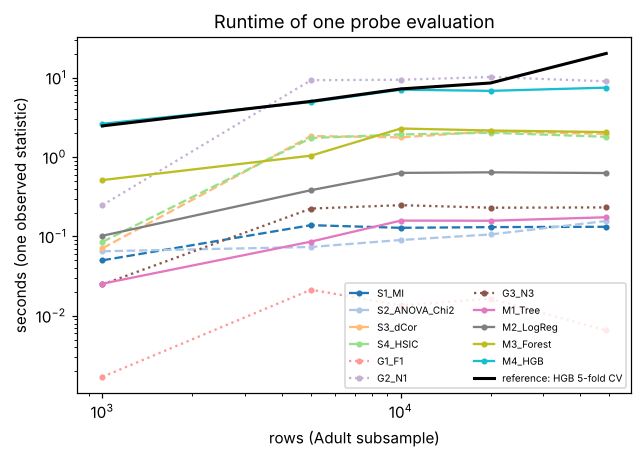

In [6]:
obs = rt[~rt.probe.str.contains("full test")]
fig, ax = plt.subplots(figsize=(6.5, 4.2))
colors = plt.cm.tab20(np.linspace(0, 1, 12))
for k, probe in enumerate(PROBE_ORDER):
    g = obs[obs.probe == probe]
    ls = "-" if FAMILY[probe] == "model-based" else ("--" if FAMILY[probe] == "statistical" else ":")
    ax.plot(g.n, g.seconds_observed, ls, marker="o", ms=3, color=colors[k], label=probe)
ref = obs.groupby("n").reference_hgb_cv_seconds.first()
ax.plot(ref.index, ref.values, "k-", lw=2, label="reference: HGB 5-fold CV")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("rows (Adult subsample)"); ax.set_ylabel("seconds (one observed statistic)")
ax.legend(fontsize=6.5, ncol=2)
ax.set_title("Runtime of one probe evaluation")
plt.savefig(os.path.join(FIG_DIR, "runtime.png"), dpi=200, bbox_inches="tight")
plt.show()